# Toulouse Participatory Budget: What Did Citizens Vote For?

Toulouse lets residents propose small projects for their neighbourhood and then vote on them. This notebook looks at the projects and the ballots to answer six questions:

1. Which kinds of projects get the most votes?
2. How do people use their votes?
3. Does a project's cost affect how many votes it gets?
4. Do people vote only for their own district?
5. If the budget were spent in vote order, would the city centre take an unfair share?
6. Who votes for "unpleasant but necessary" projects like waste and recycling?

**Data:** `data/projects.csv` (one row per project: category, cost, district, votes) and `data/voters.csv` (one row per voter: the IDs of the projects they voted for).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

## Load and prepare the data

In [2]:
projects = pd.read_csv("data/projects.csv", sep=";")
voters = pd.read_csv("data/voters.csv", sep=";")

# "10 - Jolimont / Soupetard / ..." -> id "10" and the district name
projects[["district_id", "district_name"]] = projects["district"].str.split(" - ", n=1, expand=True)

# "35,36,34" -> [35, 36, 34]
voters["project_ids"] = voters["vote"].astype(str).str.split(",").apply(
    lambda ids: [int(i) for i in ids if i.strip().isdigit()]
)
voters["n_votes"] = voters["project_ids"].str.len()

# One row per (voter, project) so we can join project details onto each vote
votes = (voters.explode("project_ids")
               .rename(columns={"project_ids": "project_id"})
               .astype({"project_id": int})
               .merge(projects[["project_id", "category", "cost", "district_id", "district_name"]],
                      on="project_id", how="left"))

print(f"{len(projects)} projects, {len(voters)} voters, {len(votes)} individual votes")
print("Votes that don't match a project:", votes["category"].isna().sum())
print("Check: ballots add up to the project vote totals ->", len(votes) == projects["votes"].sum())

199 projects, 4532 voters, 11606 individual votes
Votes that don't match a project: 0
Check: ballots add up to the project vote totals -> True


## 1. Which kinds of projects get the most votes?

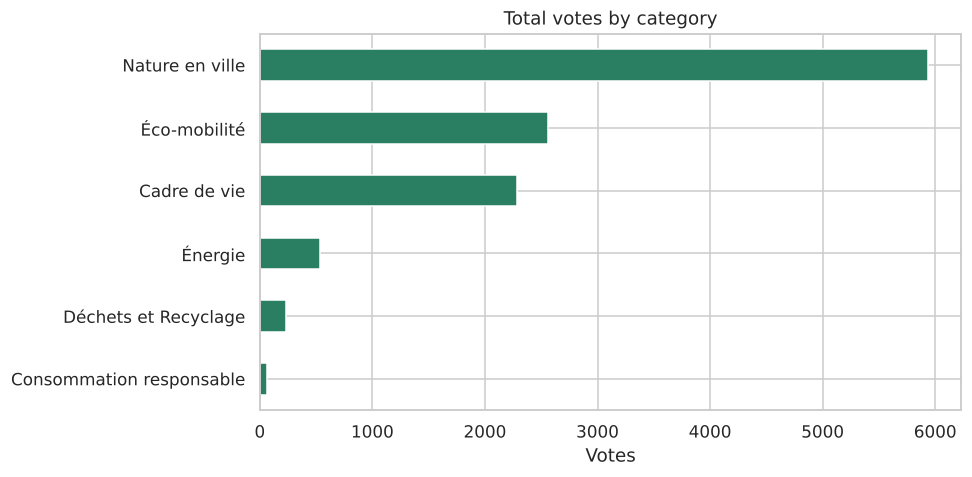

,projects,votes,share_of_votes
category,,,
Nature en ville,78,5936,0.511
Éco-mobilité,35,2562,0.221
Cadre de vie,72,2281,0.197
Énergie,7,531,0.046
Déchets et Recyclage,5,235,0.020
Consommation responsable,2,61,0.005


In [3]:
by_category = (projects.groupby("category")
                       .agg(projects=("project_id", "count"), votes=("votes", "sum"))
                       .sort_values("votes"))
by_category["share_of_votes"] = (by_category["votes"] / by_category["votes"].sum()).round(3)

by_category["votes"].plot(kind="barh", color="#2a7f62", figsize=(9, 4.5))
plt.title("Total votes by category")
plt.xlabel("Votes")
plt.ylabel("")
plt.tight_layout()
plt.show()

by_category.sort_values("votes", ascending=False)

**Finding:** "Nature en ville" (greening, trees, parks) is the clear favourite with about half of all votes. Eco-mobility (bike lanes, pedestrian safety) comes second. Waste, energy and responsible consumption projects get very little support, partly because there are very few of them.

## 2. How do people use their votes?

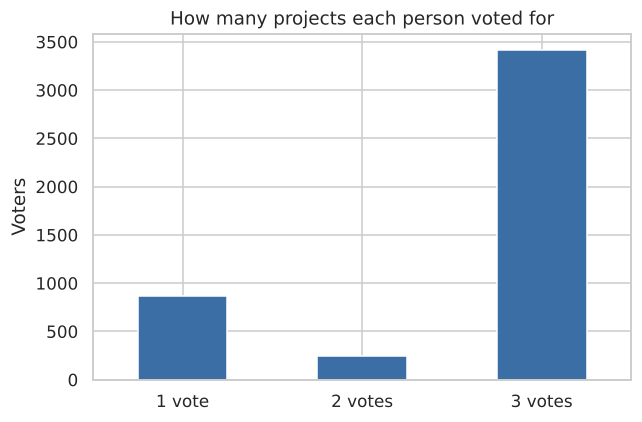

1 vote     0.192
2 votes    0.054
3 votes    0.753
Name: count, dtype: float64

In [4]:
vote_counts = voters["n_votes"].value_counts().sort_index()
vote_counts.index = [f"{n} vote{'s' if n > 1 else ''}" for n in vote_counts.index]

vote_counts.plot(kind="bar", color="#3b6ea5", rot=0, figsize=(6, 4))
plt.title("How many projects each person voted for")
plt.ylabel("Voters")
plt.tight_layout()
plt.show()

(vote_counts / vote_counts.sum()).round(3)

In [5]:
multi = votes[votes["voter_id"].isin(voters.loc[voters["n_votes"] > 1, "voter_id"])]
per_voter = multi.groupby("voter_id").agg(categories=("category", "nunique"),
                                          districts=("district_id", "nunique"))

summary = pd.DataFrame({
    "Only one category": [(per_voter["categories"] == 1).mean()],
    "Only one district": [(per_voter["districts"] == 1).mean()],
}, index=["Share of voters who cast 2+ votes"]).round(3)
summary

,Only one category,Only one district
Share of voters who cast 2+ votes,0.204,0.498


**Finding:** about three in four people used all three of their votes. Among people who voted more than once, most spread their votes across different categories, so they are not single-issue voters. About half kept all their votes inside a single district.

## 3. Does a project's cost affect how many votes it gets?

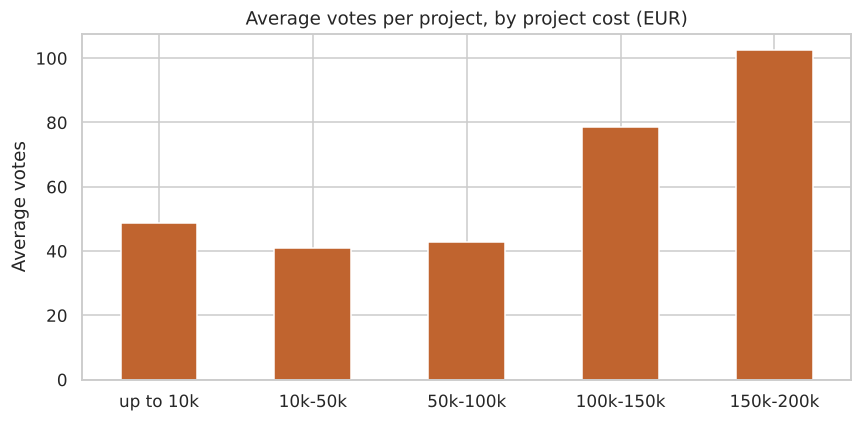

Correlation between cost and votes: 0.32


,count,mean,median
cost_band,,,
up to 10k,34,48.7,36.5
10k-50k,61,41.1,30.0
50k-100k,45,42.8,27.0
100k-150k,22,78.6,46.5
150k-200k,37,102.5,83.0


In [6]:
bands = [0, 10_000, 50_000, 100_000, 150_000, 200_001]
labels = ["up to 10k", "10k-50k", "50k-100k", "100k-150k", "150k-200k"]
projects["cost_band"] = pd.cut(projects["cost"], bands, labels=labels)

by_cost = projects.groupby("cost_band", observed=True)["votes"].agg(["count", "mean", "median"]).round(1)

by_cost["mean"].plot(kind="bar", color="#c0642f", rot=0, figsize=(8, 4))
plt.title("Average votes per project, by project cost (EUR)")
plt.ylabel("Average votes")
plt.xlabel("")
plt.tight_layout()
plt.show()

print("Correlation between cost and votes:", round(projects["cost"].corr(projects["votes"]), 2))
by_cost

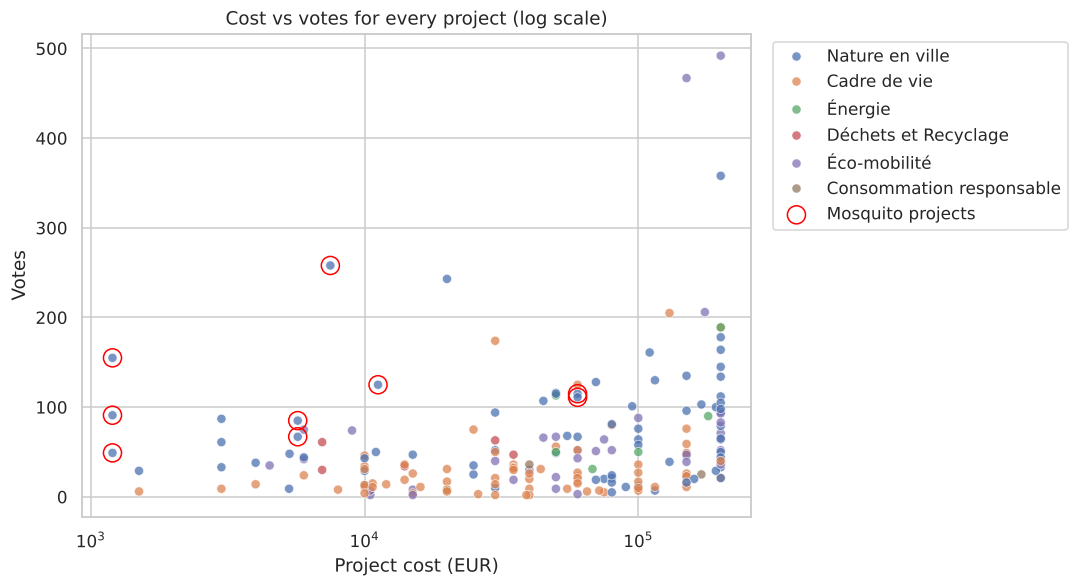

In [7]:
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.scatterplot(data=projects, x="cost", y="votes", hue="category", alpha=0.75, ax=ax)

mosquito = projects[projects["name"].str.contains("moustique", case=False, na=False)]
ax.scatter(mosquito["cost"], mosquito["votes"], s=140, facecolors="none", edgecolors="red",
           label="Mosquito projects")

ax.set_xscale("log")
ax.set_title("Cost vs votes for every project (log scale)")
ax.set_xlabel("Project cost (EUR)")
ax.set_ylabel("Votes")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [8]:
projects["votes_per_1000_eur"] = projects["votes"] / (projects["cost"] / 1000)
projects.nlargest(5, "votes_per_1000_eur")[["name", "cost", "votes", "votes_per_1000_eur"]].round(1)

,name,cost,votes,votes_per_1000_eur
118,Lutter contre les moustiques avec les chauves-...,1200.0,155,129.2
77,Pièges à moustiques tigres,1200.0,91,75.8
17,Installation de pièges à moustiques à Croix Da...,1200.0,49,40.8
76,Lutte anti-moustiques,7500.0,258,34.4
27,Installation de ruches urbaines,3000.0,87,29.0


**Finding:** bigger projects get more votes overall. Projects costing 150k-200k EUR get about twice the average votes of cheaper ones, and the correlation between cost and votes is positive (about 0.3). The exception is small mosquito-control projects: at 1,200-7,500 EUR they drew between 49 and 258 votes, which makes them by far the best value per euro.

## 4. If the budget were spent in vote order, would the city centre take an unfair share?

Simple simulation: fund projects from most to least voted until 8M EUR is spent, then see where the money goes. (This is a simplification of how the city actually picks winners.)

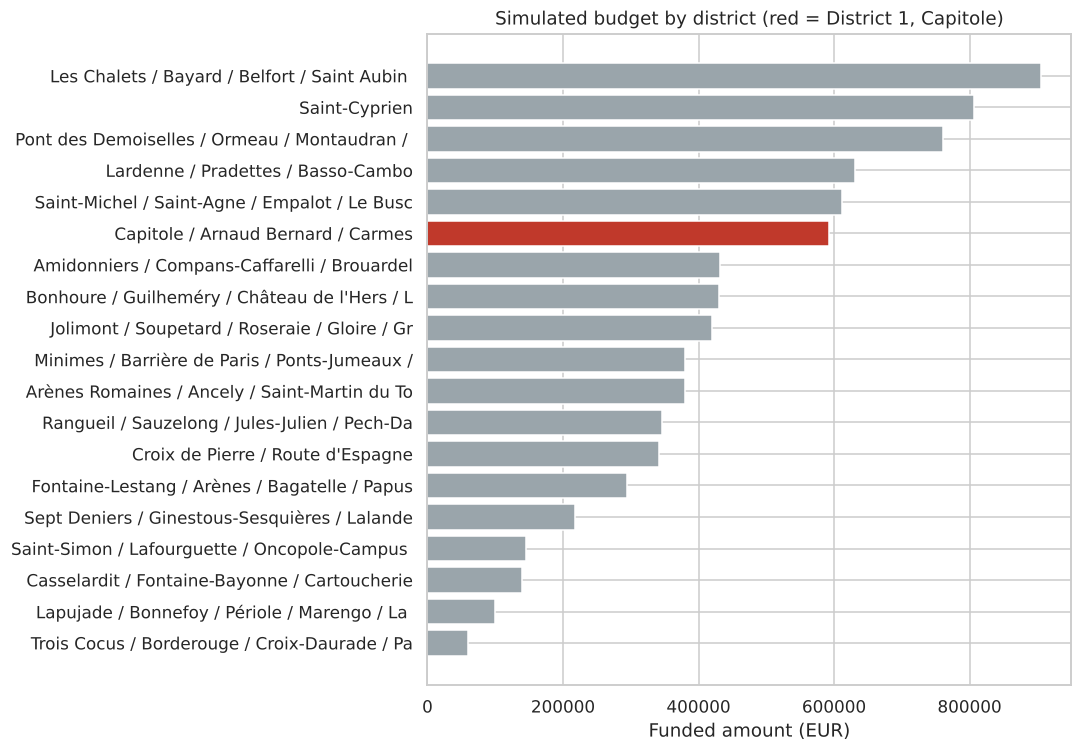

77 projects funded, 7,993,000 EUR
District 1 share: 7.4% (an equal split across 20 districts would be 5%)


In [9]:
BUDGET = 8_000_000
ranked = projects.sort_values("votes", ascending=False).copy()
ranked["cumulative_cost"] = ranked["cost"].cumsum()
funded = ranked[ranked["cumulative_cost"] <= BUDGET]

by_district = funded.groupby(["district_id", "district_name"])["cost"].sum().reset_index().sort_values("cost")
colors = ["#c0392b" if d == "1" else "#9aa5ab" for d in by_district["district_id"]]

plt.figure(figsize=(10, 7))
plt.barh(by_district["district_name"].str.slice(0, 45), by_district["cost"], color=colors)
plt.title("Simulated budget by district (red = District 1, Capitole)")
plt.xlabel("Funded amount (EUR)")
plt.tight_layout()
plt.show()

centre_share = funded.loc[funded["district_id"] == "1", "cost"].sum() / funded["cost"].sum()
print(f"{len(funded)} projects funded, {funded['cost'].sum():,.0f} EUR")
print(f"District 1 share: {centre_share:.1%} (an equal split across 20 districts would be 5%)")

**Finding:** the city centre does not dominate. District 1 gets about 7% of the simulated budget, a little above an equal 5% share. The money is spread across most districts.

## 5. Which districts support ecological projects most?

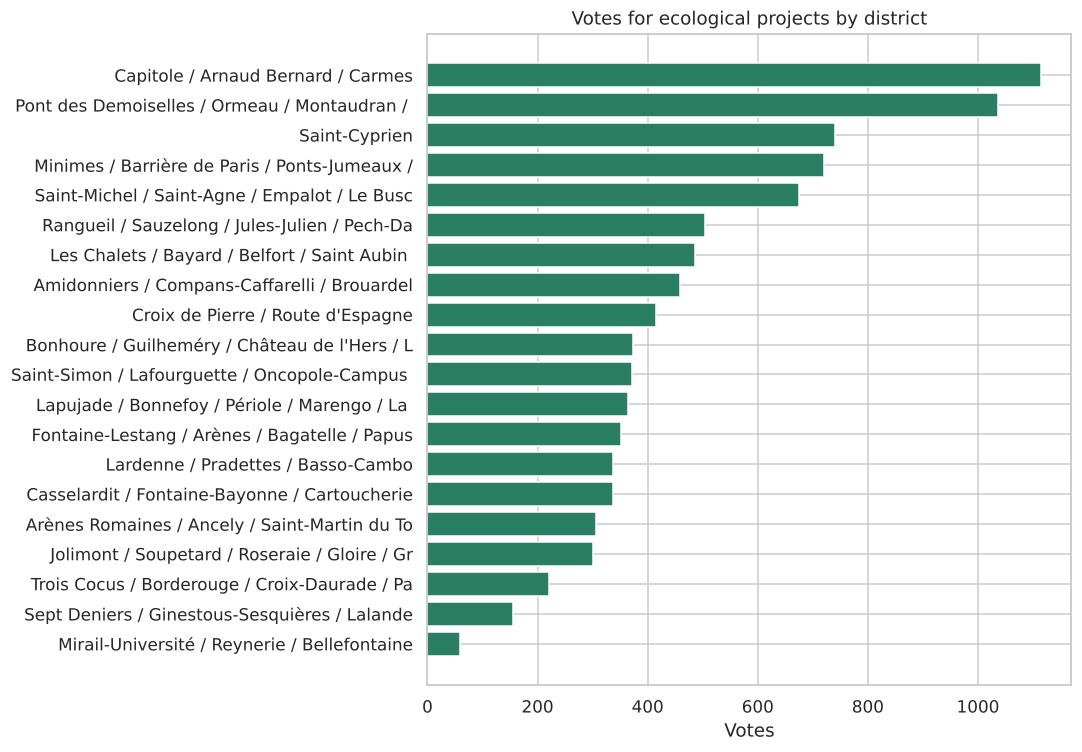

district_name
Capitole / Arnaud Bernard / Carmes                                             1114
Pont des Demoiselles / Ormeau / Montaudran / La Terrasse / Malepère            1036
Saint-Cyprien                                                                   741
Minimes / Barrière de Paris / Ponts-Jumeaux / La Vache / Raisins / Fondeyre     720
Saint-Michel / Saint-Agne / Empalot / Le Busca / Ile du Ramier / Monplaisir     674
Name: votes, dtype: int64

In [10]:
eco_categories = ["Nature en ville", "Éco-mobilité", "Déchets et Recyclage", "Énergie", "Consommation responsable"]
eco = (projects[projects["category"].isin(eco_categories)]
       .groupby("district_name")["votes"].sum().sort_values())

plt.figure(figsize=(10, 7))
plt.barh(eco.index.str.slice(0, 45), eco.values, color="#2a7f62")
plt.title("Votes for ecological projects by district")
plt.xlabel("Votes")
plt.tight_layout()
plt.show()

eco.sort_values(ascending=False).head(5)

**Finding:** the city centre (Capitole) casts the most votes for ecological projects, closely followed by Pont des Demoiselles / Montaudran. Part of this is simply that these districts proposed more ecological projects.

## 6. Who votes for waste and recycling projects?

For each vote on a "Déchets et Recyclage" project, we look at the rest of that voter's ballot:
- **Local:** they also voted for another project in the same district
- **Outsider:** their other votes were in different districts
- **Single-issue:** this was their only vote

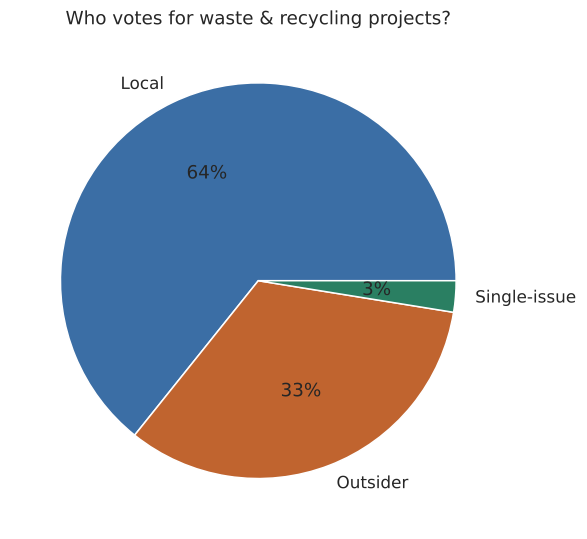

Local           151
Outsider         78
Single-issue      6
Name: count, dtype: int64

In [11]:
waste_votes = votes[votes["category"] == "Déchets et Recyclage"]

def voter_type(row):
    others = votes[(votes["voter_id"] == row["voter_id"]) & (votes["project_id"] != row["project_id"])]
    if (others["district_id"] == row["district_id"]).any():
        return "Local"
    if len(others) > 0:
        return "Outsider"
    return "Single-issue"

waste_types = waste_votes.apply(voter_type, axis=1).value_counts()

waste_types.plot(kind="pie", autopct="%1.0f%%", colors=["#3b6ea5", "#c0642f", "#2a7f62"], figsize=(5.5, 5.5))
plt.title("Who votes for waste & recycling projects?")
plt.ylabel("")
plt.tight_layout()
plt.show()

waste_types

**Finding:** most support for waste and recycling projects comes from locals: about two thirds of those voters also backed another project in the same district. So these projects are not mainly pushed by people from elsewhere.

## Summary

- Greening the city is the top priority: "Nature en ville" gets about half of all votes.
- Most people use all three votes and spread them across categories.
- Larger projects attract more votes overall, but small mosquito-control projects give by far the most votes per euro.
- Waste and recycling projects are backed mostly by local voters.
- Funding in vote order does not concentrate money in the city centre.

**Limitations:** this looks at one edition of the vote; the budget simulation is simplified; and "local" voters are inferred from the rest of their ballot, because the data has no home addresses.